<p style="background-color:darkblue;font-family:arial;font-size:250%;color:white;text-align:center;border-radius:16px 16px;"><b>Detection of product defects using Yolov7</b></p>

In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [109]:
import os
import shutil

os.makedirs(
    '/content/drive/MyDrive/ProductDefect/weights',
    exist_ok=True
)

shutil.copy(
    '/content/y7-prdef.pt',
    '/content/drive/MyDrive/ProductDefect/weights/y7-prdef.pt'
)

'/content/drive/MyDrive/ProductDefect/weights/y7-prdef.pt'

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
# ชี้ตรงไปยังไฟล์ jarlids_annots.csv ที่อยู่ภายในโฟลเดอร์ archive
csv_path = '/content/drive/MyDrive/Project Image Processing/archive/jarlids_annots.csv'

df = pd.read_csv(csv_path)

print(df.head())
print("\nชื่อคอลัมน์:")
print(df.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Unnamed: 0 filename  file_size file_attributes  region_count  region_id  \
0           0   p1.JPG     167996              {}            12          0   
1           1   p1.JPG     167996              {}            12          1   
2           2   p1.JPG     167996              {}            12          2   
3           3   p1.JPG     167996              {}            12          3   
4           4   p1.JPG     167996              {}            12          4   

                             region_shape_attributes   region_attributes  
0  {"name":"rect","x":70,"y":46,"width":120,"heig...   {"type":"intact"}  
1  {"name":"rect","x":195,"y":60,"width":118,"hei...   {"type":"intact"}  
2  {"name":"rect","x":318,"y":25,"width":144,"hei...  {"type":"damaged"}  
3  {"name":"rect","x":474,"y":13,"width":135,"hei...   {"type":"intact"}  
4  {"name":"rect","x":45,"y

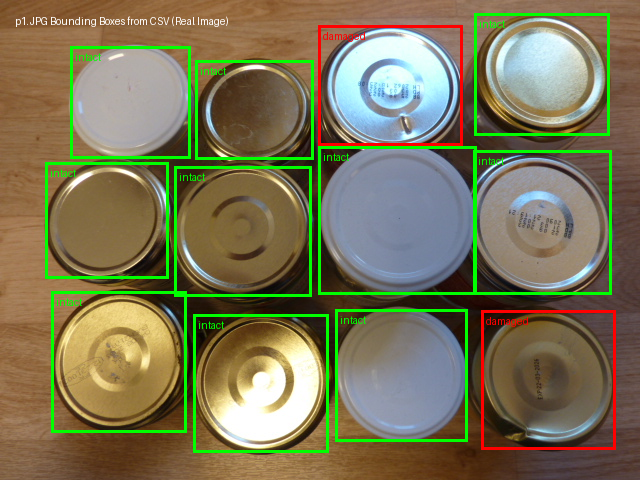

In [ ]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw, ImageFont
import os

# กำหนดโฟลเดอร์ปลายทางที่มีรูปภาพและไฟล์ CSV
archive_dir = '/content/drive/MyDrive/Project Image Processing/archive'
img_path = os.path.join(archive_dir, 'p1.JPG')

# กรองข้อมูลพิกัดของไฟล์ 'p1.JPG' จาก DataFrame ที่ได้จาก CSV
df_p1 = df[df['filename'] == 'p1.JPG'].reset_index(drop=True)

if os.path.exists(img_path):
    # เปิดรูปภาพจริงจากในโฟลเดอร์ archive
    img = Image.open(img_path)
    draw = ImageDraw.Draw(img)

    try:
        font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 14)
    except:
        font = ImageFont.load_default()

    # วาดพิกัดกล่องจากข้อมูลใน CSV ลงบนภาพจริง
    for idx, row in df_p1.iterrows():
        # แปลงข้อมูล shape attributes จาก JSON string
        shape = json.loads(row['region_shape_attributes'])
        attr = json.loads(row['region_attributes'])

        x = shape['x']
        y = shape['y']
        w = shape['width']
        h = shape['height']
        label = attr.get('type', 'unknown')

        # กำหนดสีตามประเภท
        color = (255, 0, 0) if label == 'damaged' else (0, 255, 0) # แดง = เสียหาย, เขียว = ปกติ

        # วาดกรอบสี่เหลี่ยมรอบวัตถุ
        draw.rectangle([x, y, x + w, y + h], outline=color, width=3)
        # เขียนข้อความกำกับคลาส
        draw.text((x + 5, y + 5), label, fill=color, font=font)

    # วาดข้อความหัวเรื่องบนภาพ
    draw.text((15, 15), "p1.JPG Bounding Boxes from CSV (Real Image)", fill=(255, 255, 255), font=font)

    display(img)
else:
    print(f"ไม่พบไฟล์รูปภาพจริงในพาธ: {img_path} กรุณาตรวจสอบชื่อไฟล์อีกครั้ง")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


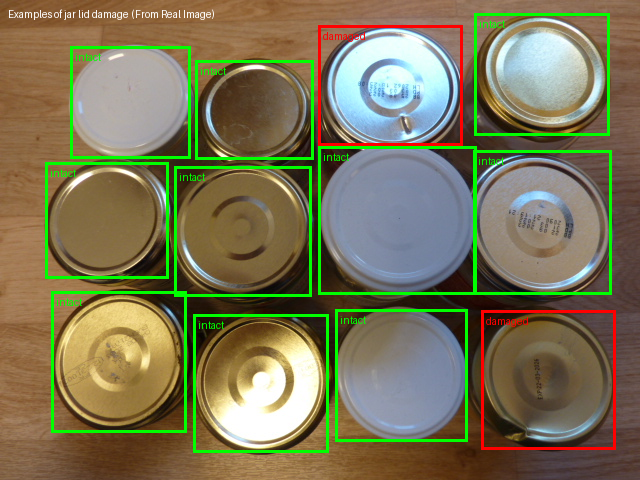

In [ ]:
from google.colab import drive
from PIL import Image, ImageDraw, ImageFont
import os
import json

drive.mount('/content/drive')
archive_dir = '/content/drive/MyDrive/Project Image Processing/archive'

# ตั้งค่าความกว้างและส่วนสูงจำลอง (ปกติภาพในชุดข้อมูลนี้จะเป็น 640x480)
width, height = 640, 480

# กรองข้อมูลพิกัดของไฟล์ 'p1.JPG' จาก DataFrame ที่มีอยู่
df_p1 = df[df['filename'] == 'p1.JPG'].reset_index(drop=True)

# ตรวจสอบว่ามีไฟล์จริงหรือไม่
img_path = os.path.join(archive_dir, 'p1.JPG')
if os.path.exists(img_path):
    img = Image.open(img_path)
else:
    print("ไม่พบไฟล์รูปภาพจริงใน Drive จะทำการสร้างภาพจำลองและวาดตำแหน่งกล่อง (Bounding Box) จากข้อมูลใน CSV")
    img = Image.new('RGB', (width, height), color=(50, 50, 65))

i1 = ImageDraw.Draw(img)

try:
    font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 16)
except:
    font = ImageFont.load_default()

# วาดข้อมูลพิกัดที่พบในตาราง CSV
for idx, row in df_p1.iterrows():
    shape = json.loads(row['region_shape_attributes'])
    attr = json.loads(row['region_attributes'])

    x = shape['x']
    y = shape['y']
    w = shape['width']
    h = shape['height']
    label = attr.get('type', 'unknown')

    color = (255, 0, 0) if label == 'damaged' else (0, 255, 0)
    i1.rectangle([x, y, x + w, y + h], outline=color, width=3)
    i1.text((x + 5, y + 5), label, fill=color, font=font)

i1.text(
    (8, 8),
    'Examples of jar lid damage (From Real Image)',
    font=font,
    fill=(255, 255, 255)
)

display(img)

<a id="Installation-packages"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Installation packages</b></p>

We start with installing the needed packages. Do not forget to set the accelerator in the right panel at GPU.

In [ ]:
!git clone https://github.com/WongKinYiu/yolov7
!cd yolov7 && wget https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7.pt

Cloning into 'yolov7'...
remote: Enumerating objects: 1197, done.
remote: Total 1197 (delta 0), reused 0 (delta 0), pack-reused 1197 (from 1)
Receiving objects: 100% (1197/1197), 74.29 MiB | 16.86 MiB/s, done.
Resolving deltas: 100% (511/511), done.
--2026-10-31 21:16:09--  https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7.pt
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/511187726/b0243edf-9fb0-4337-95e1-42555f1b37cf?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-31T22%3A07%3A48Z&rscd=attachment%3B+filename%3Dyolov7.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-31T21%3A07%3A10Z&ske=2026-10-31T22%3A07%3A48Z&sks=b&skv=2018-11-09&sig=w5xqE5GsF6ZcBozaO%2BDQcl80jqQTLebA%2Bw5D6szH

In [ ]:
!pip install imagesize

In [ ]:
!pip install ptitprince

The following modules will be used:

In [ ]:
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import json
import sys
import os
import shutil
from distutils.dir_util import copy_tree
import imagesize
import ptitprince as pt
from shutil import copyfile
import time
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patches as mpatches
import seaborn as sns
import re

Yolov7 is setting the seed automatically at 0 for `random.seed`, `np.random.seed` and `init_torch_seeds` in the function init_seeds that can be found in `yolov7/utils/general.py`. Note however that complete reproducibility across algorithm releases and CPU/GPU is not garanteed.

In [ ]:
!grep -w init_seeds 'yolov7/utils/general.py' -A 4

def init_seeds(seed=0):
    # Initialize random number generator (RNG) seeds
    random.seed(seed)
    np.random.seed(seed)
    init_torch_seeds(seed)


<a id="Image-data"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Image data and annotations</b></p>

Photos were taken using a Panasonic camera (DMC-TZ7). All images were width 640 by height 480 pixels. Photos contained multiple glass jars with jar lids that were intact or damaged. Damage could be subtle or severe, and categories were holes, deformations or scratches. Since there was a lack of training data, these categories were merged to a single category. There are a variety of confounding factors that make it difficult for machine vision to detect defects, such as luminance variation, light reflection and color. Jars were photographed in different positions and were rotated randomly.
Training data consisted of 124 images and validation of 39 images. 5 unseen test images were added as well. Data were annotated using the VGG Image Annotator (VIA) <span style="color:blue">[5]</span>.

<a id="Data-preprocessing"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Data preprocessing</b></p>

Running `prepare_annotations()`, first the pandas DataFrame containing the annotation data is loaded.
A directory structure is created which will contain the image files and label data. Label data are bounding box data normalized between 0 and 1. Data is split into a train and validation set.

In [ ]:
import os

# ปรับเส้นทางไปที่ไฟล์จริงบน Google Drive
annots = '/content/drive/MyDrive/Project Image Processing/archive/jarlids_annots.csv'
imagefiles = '/content/drive/MyDrive/Project Image Processing/archive/'

# เก็บไฟล์ปลายทางสำหรับการรันบนพื้นที่ Local ของ Colab
dest = '/content/dest/'
results = '/content/results.txt'

In [ ]:
yfile='train.yaml'
tr_start=1
tr_end=125
va_start=200
va_end=239
te_start=1
te_end=6
va_te='val.txt'

In [ ]:
class prepare_annotations():
    def __init__(self, sourcedir=annots, imagesdir=imagefiles, destdir=dest, namedir=dest, yamlfile=yfile, filename='im1.jpg', trainstart=tr_start, trainend=tr_end, valstart=va_start, valend=va_end, teststart=te_start, testend=te_end, validationtest=va_te):
        self.sourcedir = sourcedir # directory where annotation data in CSV format are.
        self.imagesdir = imagesdir # directory where original images are.
        self.destdir = destdir # directory where annotations should be put.
        self.namedir = namedir # directory where files are read when Yolov is run; paths are in the .txt and .yaml
        self.yamlfile = yamlfile # name given to the yamlfile
        self.filename = filename # for ex. p1.jpg
        self.trainstart = trainstart # where train data start
        self.trainend = trainend # where train data end (not including)
        self.valstart = valstart # where validation data start
        self.valend = valend # where validation data end (not including)
        self.teststart = teststart # where testdata start
        self.testend = testend # where testdata end
        self.validationtest = validationtest # name of file used in test, can be 'val.txt' or 'test.txt'

    def isize(self, imagesdir, filename):
        """
        Measures image dimensions without loading the image, using the package imagesize.
        imagesdir: path directory to the image files
        filename: name of image file
        """
        w, h = imagesize.get(os.path.join(imagesdir, filename))
        return(w, h)

    def load_dataframe(self):
        """
        Loads annotation data with bounding box information and performs preprocessing
        """
        dat = pd.read_csv(self.sourcedir)
        tr = ['p'+str(s)+'.JPG' for s in range(self.trainstart, self.trainend)]
        va = ['p'+str(s)+'.JPG' for s in range(self.valstart, self.valend)]
        te = ['t'+str(s)+'.JPG' for s in range(self.teststart, self.testend)]
        for i,j in zip(['train', 'val', 'test'], [tr, va, te] ):
            dat.loc[dat['filename'].isin(j), 'dataset'] = i
        dat['region_attributes']= dat['region_attributes'].replace({'{}': 'None'})
        dat = dat[~dat['region_attributes'].isin(['None'])].reset_index(drop=False)
        dat['category_names'] = dat['region_attributes'].apply(lambda x: str(list(eval(x).values())[0]))
        dat['category_codes'] = dat[['category_names']].apply(lambda x: pd.Categorical(x).codes)
        dat['image_width'] = dat['filename'].apply(lambda x: self.isize(self.imagesdir, x)[0])
        dat['image_height'] = dat['filename'].apply(lambda x: self.isize(self.imagesdir, x)[1])
        dat['x_min'] = dat['region_shape_attributes'].apply(lambda x: eval(x)['x'])
        dat['y_min'] = dat['region_shape_attributes'].apply(lambda x: eval(x)['y'])
        dat['bb_width'] = dat['region_shape_attributes'].apply(lambda x: eval(x)['width'])
        dat['bb_height'] = dat['region_shape_attributes'].apply(lambda x: eval(x)['height'])
        dat['n_x_center'] = (((dat['x_min'] + dat['bb_width']) + dat['x_min']) / 2) / dat['image_width']
        dat['n_y_center'] = (((dat['y_min'] + dat['bb_height']) + dat['y_min']) / 2) / dat['image_height']
        dat['n_width'] = dat['bb_width'] / dat['image_width']
        dat['n_height'] = dat['bb_height'] / dat['image_height']
        dat['color_cat'] = dat['category_names'].replace({'intact': 'green', 'damaged': 'red'})
        dat = dat.reset_index(drop=True)
        return(dat)

    def make_dirstructure(self):
        """
        Creates directory structure and copies image files
        """
        try:
            print('new directory tree prepared')
            os.makedirs(self.destdir, exist_ok=True)
            os.makedirs(os.path.join(self.destdir, 'images/'), exist_ok=True)
            os.makedirs(os.path.join(self.destdir, 'labels/'), exist_ok=True)
        except:
            print('no new directory was made, probably already existing')

        dat = self.load_dataframe()
        filenames = list(set(dat['filename']))
        for f in filenames:
            copyfile(os.path.join(self.imagesdir, f), os.path.join(self.destdir, 'images', f))

    def make_labels(self):
        """
        Saves bounding box data for given filenames as txt file for each image.
        """
        dat = self.load_dataframe()
        print('length data:', len(dat))
        print('Emptying labelfiles')
        for i in list(set(dat['filename'])):
            try:
                os.remove(os.path.join(self.destdir, 'labels/', i[:-4]+'.txt'))
            except:
                pass

        print('Collecting bounding boxes, saving them to:', os.path.join(self.destdir, 'labels/'))
        for i in range(0,len(dat)):
            try:
                with open(os.path.join(self.destdir, 'labels/', dat['filename'][i][:-4]+'.txt'), "a") as f:
                    print(dat['category_codes'][i], dat['n_x_center'][i], dat['n_y_center'][i], dat['n_width'][i], dat['n_height'][i], file=f)
            except:
                print('something went wrong at', i)

    def fixed_train_val_split(self):
        """
        Images are separated given index. Images that contained the same jarlids but photographed from a different angle were in the same split
        """
        dat = self.load_dataframe()

        tr = ['p'+str(i)+'.JPG' for i in range(self.trainstart,self.trainend)]
        va = ['p'+str(i)+'.JPG' for i in range(self.valstart, self.valend)]
        te = ['t'+str(i)+'.JPG' for i in range(self.teststart, self.testend)]
        print('Splitting train and validation data')

        try:
            print("Removed previous files")
            os.remove('train.txt')
            os.remove('val.txt')
            os.remove('test.txt')
        except:
            print("No previous files train.txt, val.txt or test.txt were found")

        with open(os.path.join(self.destdir, 'train.txt'), "a") as f:
            for i in range(len(tr)):
                print(os.path.join(self.namedir, 'images', tr[i]), file=f)
        with open(os.path.join(self.destdir, 'val.txt'), "a") as f:
            for i in range(len(va)):
                print(os.path.join(self.namedir, 'images', va[i]), file=f)
        with open(os.path.join(self.destdir, 'test.txt'), "a") as f:
            for i in range(len(te)):
                print(os.path.join(self.namedir, 'images', te[i]), file=f)

    def yaml_file(self):
        """
        *lb: labels such as 'cat', 'dog'
        namedir: # name directory where Docker Yolov5 reads the files.
        yamlfile: name of the design file
        validationtest: requires val.txt or test.txt
        """
        dat = self.load_dataframe()
        lb = list(sorted(set(dat['category_names'])))

        with open(os.path.join(self.destdir, self.yamlfile), "a") as f:
            print('yaml:', file=f)
            print('names:', file=f)
            for i in lb:
                print('- ', i, file=f)
            print('nc:', len(lb), file=f)
            print('train: ', os.path.join(self.namedir, 'train.txt'), file=f)
            print('val: ', os.path.join(self.namedir, self.validationtest), file=f)

In [ ]:
df = prepare_annotations().load_dataframe()

In [ ]:
df.head()

,index,Unnamed: 0,filename,file_size,file_attributes,...,n_x_center,n_y_center,n_width,n_height,color_cat
0,0,0,p1.JPG,167996,{},...,0.203125,0.212500,0.187500,0.233333,green
1,1,1,p1.JPG,167996,{},...,0.396875,0.228125,0.184375,0.206250,green
2,2,2,p1.JPG,167996,{},...,0.609375,0.177083,0.225000,0.250000,red
3,3,3,p1.JPG,167996,{},...,0.846094,0.154167,0.210938,0.254167,green
4,4,4,p1.JPG,167996,{},...,0.166406,0.458333,0.192188,0.241667,green


<a id="Visualization"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Visualization and annotation boxes</b></p>

Let us visualize the annotations. This can of course also be done with the VGG Image Annotator which was used for annotation <span style="color:blue">[5]</span>.

In [ ]:
def visualisation_annotations(dat, filedir, fname):
    """
    dat: input pandas DataFrame
    filedir: directory where image files can be found
    fname: filename to be visualized, for ex 'p1.JPG'
    """
    im = Image.open(os.path.join(filedir, fname))
    fig, ax = plt.subplots(figsize=(14, 20))
    ax.imshow(im)
    ndat = dat[dat['filename'] == fname].reset_index()

    for i in range(len(ndat)):
        xmin = ndat['x_min'][i]
        ymin = ndat['y_min'][i]
        w = ndat['bb_width'][i]
        h = ndat['bb_height'][i]
        color = ndat['color_cat'][i]
        rect = patches.Rectangle((xmin, ymin), w, h, linewidth=2, edgecolor=color, facecolor='none') # takes x, y, width and height.
        ax.add_patch(rect)

    mpatches_dat = pd.DataFrame(df[['category_names', 'color_cat']].value_counts().reset_index())
    patch1 = mpatches.Patch(color=mpatches_dat['color_cat'][0], label=mpatches_dat['category_names'][0])
    patch2 = mpatches.Patch(color=mpatches_dat['color_cat'][1], label=mpatches_dat['category_names'][1])
    ax.legend(handles=[patch1, patch2])

    plt.show()

In [ ]:
visualisation_annotations(df, imagefiles, 'p15.JPG')

<a id="Bounding-box"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Bounding box size</b></p>

Bounding box size may be a confounding factor and could be predictive in the train and validation set, while it is not in the unseen testdata. As can be seen in the Raincloud plot below, bounding box width and height was similar for intact and damaged jar lids.

In [ ]:
f, ax = plt.subplots(figsize=(12, 8))

pt.RainCloud(x = "category_names", y = "bb_width", data = df[df['dataset'] == 'train'], palette = "Set2", bw = .2,
                 width_viol = .6, ax = ax, orient = "h")

plt.title("Bounding box width between intact and damaged jarlids")

/usr/local/lib/python3.13/dist-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 1.0, 'Bounding box width between intact and damaged jarlids')

In [ ]:
f, ax = plt.subplots(figsize=(12, 8))

pt.RainCloud(x = "category_names", y = "bb_height", data = df[df['dataset'] == 'train'], palette = "Set2", bw = .2,
                 width_viol = .6, ax = ax, orient = "h")

plt.title("Bounding box height between intact and damaged jarlids")

/usr/local/lib/python3.13/dist-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 1.0, 'Bounding box height between intact and damaged jarlids')

A scatterplot shows that the dimensions of the bounding box have in general similar aspect ratios.

In [ ]:
plt.figure(figsize=[14,8])
sns.scatterplot(x='bb_width', y='bb_height', data=df.loc[df['dataset'] == 'train'].reset_index(), hue='category_names', alpha=0.7, s=50, palette=dict(intact="#4c9409", damaged="#d48c11"))

<Axes: xlabel='bb_width', ylabel='bb_height'>

<a id="Class-distribution"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Class distribution</b></p>

There is a slight imbalance between intact and damaged jarlids.

In [ ]:
def count_classes(dat, dataset):
    """
    dat: input DataFrame
    dataset: "train", "val", or "test"
    """
    return(df.loc[df['dataset'] == dataset, "category_names"].value_counts())

Class distribution for train data

In [ ]:
count_classes(df, "train")

,count
category_names,
intact,727
damaged,622


Class distribution for validation data

In [ ]:
count_classes(df, "val")

,count
category_names,
damaged,261
intact,219


<a id="Preparation-annotations"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Preparation of annotations</b></p>

We will continue below with the preparation of annotations in the format that is needed for Yolov7. First of all, we start by making a directory structure where the image files and annotations can be stored.

In [ ]:
# โหลดข้อมูลและเตรียมสร้าง Directory Structure บนเครื่อง Colab
# มั่นใจว่ามีการรันคลาสเตรียมข้อมูลก่อนทำงาน
prep = prepare_annotations()
prep.make_dirstructure()

new directory tree prepared


In [ ]:
# สร้างข้อมูล Labels ในรูปแบบ YOLO txt บนเครื่อง Colab
prep.make_labels()

length data: 1859
Emptying labelfiles


In [ ]:
# แยกข้อมูล Train และ Validation บนเครื่อง Colab
prep.fixed_train_val_split()

Splitting train and validation data
Removed previous files
No previous files train.txt, val.txt or test.txt were found


In [ ]:
# สร้างไฟล์สำหรับกําหนดคลาส (YAML)
prep.yaml_file()

Now the data structure is ready for training the object detection model.

In [ ]:
!cat /content/dest/train.yaml

yaml:
names:
-  damaged
-  intact
nc: 2
train:  /content/dest/train.txt
val:  /content/dest/val.txt
yaml:
names:
-  damaged
-  intact
nc: 2
train:  /content/dest/train.txt
val:  /content/dest/val.txt


We will look at the annotation data for one image file. The first column displays the category (intact or damaged), the next four columns are the normalized x_center, normalized y_center, normalized width and normalized height of each bounding box.

In [ ]:
!cat '/content/dest/labels/p1.txt'

1 0.203125 0.2125 0.1875 0.23333333333333334
1 0.396875 0.228125 0.184375 0.20625
0 0.609375 0.17708333333333334 0.225 0.25
1 0.84609375 0.15416666666666667 0.2109375 0.25416666666666665
1 0.16640625 0.4583333333333333 0.1921875 0.24166666666666667
1 0.37890625 0.48125 0.2140625 0.2708333333333333
1 0.6203125 0.4583333333333333 0.246875 0.30833333333333335
1 0.846875 0.4625 0.215625 0.3
1 0.18515625 0.753125 0.2109375 0.29375
1 0.40703125 0.7979166666666667 0.2109375 0.2875
1 0.6265625 0.78125 0.20625 0.275
0 0.85625 0.790625 0.209375 0.28958333333333336


<a id="Training"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Training</b></p>

The model will be trained using data augmentation. In the file `hypownsettings.yaml`, scaling and mosaic are set at 0 since during experiments it turned out that these settings had a negative impact on training. Flip upsidedown is set at 0.5.

In [ ]:
os.environ["WANDB_MODE"]="offline"

In [ ]:
!cp 'yolov7/cfg/training/yolov7.yaml' '/content/yolov7_ad.yaml'

In [ ]:
!cp 'yolov7/cfg/training/yolov7.yaml' '/content/yolov7_ad.yaml'
with open("/content/yolov7_ad.yaml") as r:
  text = r.read().replace("nc: 80", "nc: 2")
with open("/content/yolov7_ad.yaml", "w") as w:
  w.write(text)

In [ ]:
!head -5 '/content/yolov7_ad.yaml'

# parameters
nc: 2  # number of classes
depth_multiple: 1.0  # model depth multiple
width_multiple: 1.0  # layer channel multiple



In [ ]:
# ย้ายไดเรกทอรีไปยังตำแหน่งของโฟลเดอร์ yolov7 เพื่อเรียกสคริปต์เทรน
import os
if os.path.exists('/content/yolov7'):
    %cd /content/yolov7
else:
    print("ไม่พบโฟลเดอร์ yolov7 กรุณาตรวจสอบว่าได้ทำการ clone git ในสเต็ปบนสุดหรือยัง")

/content/yolov7


In [ ]:
!cp 'data/hyp.scratch.custom.yaml' '/content/hypownsettings.yaml'
with open("/content/hypownsettings.yaml") as r:
  text = r.read().replace("mosaic: 1.0", "mosaic: 0.0").replace("flipud: 0.0", "flipud: 0.5").replace("scale: 0.5", "scale: 0.0")
with open("/content/hypownsettings.yaml", "w") as w:
  w.write(text)

In [ ]:
import urllib.request
import torch
import sys

# เพิ่มโมดูลที่เกี่ยวข้องของ numpy และ models เข้าเซฟลิสต์ของ PyTorch เพื่ออนุญาตการโหลดโมเดลได้อย่างสมบูรณ์
try:
    import numpy as np
    # อนุญาตตัวสร้างอาร์เรย์ของ NumPy และโครงสร้างที่จำเป็น
    try:
        torch.serialization.add_safe_globals([np._core.multiarray._reconstruct])
    except:
        pass
    try:
        torch.serialization.add_safe_globals([np.dtype])
    except:
        pass
except Exception as e:
    print(f"Warning add numpy globals: {e}")

try:
    # อนุญาตโครงสร้างโมเดล YOLOv7
    sys.path.append('/content/yolov7')
    from models.yolo import Model
    from models.common import Conv, Bottleneck, SPPF, MP1, Transition, Concat
    torch.serialization.add_safe_globals([Model, Conv, Bottleneck, SPPF, MP1, Transition, Concat])
except Exception as e:
    print(f"Warning add yolo model globals: {e}")

# แก้ไขไฟล์ train.py ของ yolov7 ให้กำหนด weights_only=False เสมอ
with open('/content/yolov7/train.py', 'r') as f:
    code = f.read()

fixed_code = code.replace(
    "torch.load(weights, map_location=device)",
    "torch.load(weights, map_location=device, weights_only=False)"
)

with open('/content/yolov7/train.py', 'w') as f:
    f.write(fixed_code)

# แก้ไขไฟล์ test.py ของ yolov7 ให้กำหนด weights_only=False เสมอ
with open('/content/yolov7/test.py', 'r') as f:
    test_code = f.read()

fixed_test_code = test_code.replace(
    "torch.load(weights, map_location=device)",
    "torch.load(weights, map_location=device, weights_only=False)"
)

with open('/content/yolov7/test.py', 'w') as f:
    f.write(fixed_test_code)

print("ทำการตั้งค่า PyTorch Safe Globals และ Patch สคริปต์เรียบร้อยแล้ว!")

# เริ่มต้นรันคำสั่งฝึกสอนโมเดลผ่านสคริปต์ (โดยตั้งค่า PYTHONWARNINGS เพื่อปิดการแจ้งเตือนเรื่องความปลอดภัยขณะโหลดโมเดล)
!PYTHONWARNINGS="ignore" python /content/yolov7/train.py --img 640 --batch 16 --epochs 100 --data /content/dest/train.yaml --hyp "/content/hypownsettings.yaml" --image-weights --cfg "/content/yolov7_ad.yaml" --weights '/content/yolov7/yolov7.pt' --cache

Warning add yolo model globals: cannot import name 'MP1' from 'models.common' (/content/yolov7/models/common.py)
ทำการตั้งค่า PyTorch Safe Globals และ Patch สคริปต์เรียบร้อยแล้ว!
I0000 00:00:1793481411.992113   15808 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793481415.319481   15808 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
YOLOR 🚀 v0.1-128-ga207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Namespace(weights='/content/yolov7/yolov7.pt', cfg='/content/yolov7_ad.yaml', data='/content/dest/train.yaml', hyp='/content/hypownsettings.yaml', epochs=100, batch_size=16, img_size=[640, 640], rect=False, resume=False, nosave=False, notest=False, noautoanchor=False, evolve=False, bucket='', cache_images=True, ima

Training gives various files including a `results.txt` file that will in the following line be copied to the Kaggle working space.

In [ ]:
!cp '/content/yolov7/runs/train/exp/results.txt' '/content/results.txt'
!cp '/content/yolov7/runs/train/exp/results.png' '/content/results.png'

In [ ]:
!cp '/content/yolov7/runs/train/exp/weights/best.pt' '/content/y7-prdef.pt'

<a id="Visualization-learning"></a>
<p style="background-color:darkblue;font-family:arial;font-size:120%;color:white;text-align:center;border-radius:2px 2px;"><b>Visualization of the learning curves</b></p>

To evaluate the results for our purpose, we will look if the bounding boxes are well located around the jar lids and if the predicted class corresponds to the annotated class.
To start the visualization, we will need to replace multiple spaces with commas in the `results.txt` file, so we can display performance below.

In [ ]:
column_names = ['empty', 'x1', 'x2', 'Box', 'Objectness', 'Classification', 'x3', 'x4', 'x5', 'Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'val_Box', 'val_Obj', 'val_Class']

In [ ]:
def text_spaces(inputtext, outputtext, colnames):
    """
    removes spaces and \n from results.txt file and returns data in dataframe
    inputtext: for ex 'results.txt'
    outputtext: for ex 'results.csv'
    colnames: list with columnnames
    """
    dat = pd.DataFrame(columns=colnames)

    with open(inputtext) as f:
        lines = f.readlines()
    print('Length lines:', len(lines))

    for i in range(len(lines)):
        t1 = re.sub(' +', ', ', lines[i])
        t2 = re.sub('\n', '', t1)
        t3 = t2.split(",")
        dat.loc[i] = t3
    dat.to_csv(outputtext)

    return(dat)

In [ ]:
# ตรวจเช็คว่ามีไฟล์ results.txt และผ่านกระบวนการเทรนเสร็จสมบูรณ์เรียบร้อยแล้วหรือไม่ก่อนดึงค่า
import os
import glob
import shutil

# ตรวจค้นหาไฟล์ results.txt ในโฟลเดอร์ผลลัพธ์ของ YOLOv7 โดยอัตโนมัติ
yolov7_results = glob.glob('/content/yolov7/runs/train/exp*/results.txt')

if yolov7_results:
    # หาไฟล์ที่ได้รับการบันทึกข้อมูลล่าสุด
    latest_results_path = max(yolov7_results, key=os.path.getmtime)
    print(f"📌 ค้นพบไฟล์ผลลัพธ์ล่าสุดอัตโนมัติที่: {latest_results_path}")
    # คัดลอกไปที่ตำแหน่งหลักเพื่อรันต่อตามโค้ดมาตรฐาน
    shutil.copy(latest_results_path, results)

# ดึงข้อมูลจากไฟล์มาใช้งานต่อเมื่อตรวจสอบพบว่ามีอยู่แล้ว
if os.path.exists(results) and os.path.getsize(results) > 0:
    df_lcurves = text_spaces(inputtext=results, outputtext='/content/results_clean.csv', colnames=column_names)
    print("✅ ดึงค่าข้อมูลผลลัพธ์การฝึกสอนสำเร็จและบันทึกเป็น df_lcurves เรียบร้อยแล้ว!")
else:
    print(f"⚠️ ไม่พบไฟล์ {results} ! กระบวนการฝึกสอน (Training) ของคุณกำลังรันอยู่หรือยังไม่ผ่าน Epoch แรก จึงยังไม่มีการเขียนไฟล์ลงระบบครับ")
    print("กรุณารอให้ผลการฝึกสอนเริ่มต้นทำงานสักระยะหนึ่ง จากนั้นค่อยกลับมารันเซลล์นี้ใหม่อีกครั้งครับ")

📌 ค้นพบไฟล์ผลลัพธ์ล่าสุดอัตโนมัติที่: /content/yolov7/runs/train/exp2/results.txt
Length lines: 100
✅ ดึงค่าข้อมูลผลลัพธ์การฝึกสอนสำเร็จและบันทึกเป็น df_lcurves เรียบร้อยแล้ว!


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import sys

# ตรวจสอบว่าตัวแปร df_lcurves ได้รับการสร้างไว้ก่อนหน้านี้หรือยัง
if 'df_lcurves' not in locals() and 'df_lcurves' not in globals():
    print("⚠️ [คำแนะนำ] ยังไม่สามารถวาดกราฟได้ในขณะนี้ เนื่องจากโมเดลกำลังเทรนอยู่หรือยังรันไม่เสร็จ!")
    print("กรุณารอจนกระทั่งกระบวนการเทรนเสร็จสิ้น (หรือมีล็อกบันทึกใน results.txt แล้ว) แล้วค่อยรันเซลล์นี้ใหม่อีกครั้งนะครับ")
else:
    # ตั้งค่าสไตล์การวาดกราฟโดยระบุเป็นเวอร์ชันที่เข้ากันได้กับ Matplotlib ใหม่และเก่า
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except:
        plt.style.use('default') # ใช้สไตล์พื้นฐานถ้าหาชื่อระบุไม่ได้

    plt.figure(figsize = (14, 10))

    line1 = ['Box', 'Objectness', 'Classification', 'Precision', 'mAP@0.5']
    line2 = ['val_Box', 'val_Obj', 'val_Class', 'Recall', 'mAP@0.5:0.95']
    col1 = ['blue', 'blue', 'blue', 'green', 'green']
    col2 = ['red', 'red', 'red', 'orange', 'orange']
    ylab = ['box_loss', 'obj_loss', 'cls_loss', 'recall and precision', 'mAP']
    p1 = ['train', 'train', 'train', 'precision', 'mAP_0.5']
    p2 = ['val', 'val', 'val', 'recall', 'mAP_0.5:0.95']

    # ตรวจสอบความถูกต้องและแปลงข้อมูลเป็น float
    df_lcurves[line1] = df_lcurves[line1].astype(float)
    df_lcurves[line2] = df_lcurves[line2].astype(float)

    for i in range(len(line1)):
        ax = plt.subplot(3, 2, i+1)
        ax.plot(df_lcurves[line1[i]], '.-', color=col1[i])
        ax.plot(df_lcurves[line2[i]], '.-', color=col2[i])
        ax.set_ylabel(ylab[i])
        patch1 = mpatches.Patch(color=col1[i], label=p1[i])
        patch2 = mpatches.Patch(color=col2[i], label=p2[i])
        ax.legend(handles=[patch1, patch2])

    plt.tight_layout()
    plt.show()

แก้ไฟล์

In [ ]:
file_path = '/content/yolov7/models/experimental.py'

with open(file_path, 'r') as f:
    content = f.read()

content = content.replace(
    'torch.load(w, map_location=map_location)',
    'torch.load(w, map_location=map_location, weights_only=False)'
)

with open(file_path, 'w') as f:
    f.write(content)

print("แก้ไข experimental.py เรียบร้อย")

แก้ไข experimental.py เรียบร้อย


In [ ]:
file_path = '/content/yolov7/utils/datasets.py'

with open(file_path, 'r') as f:
    content = f.read()

content = content.replace(
    'torch.load(cache_path)',
    'torch.load(cache_path, weights_only=False)'
)

with open(file_path, 'w') as f:
    f.write(content)

print("แก้ไข datasets.py เรียบร้อย")

แก้ไข datasets.py เรียบร้อย


In [ ]:
import glob
import os

cache_files = glob.glob('/content/dest/**/*.cache', recursive=True)

for file in cache_files:
    os.remove(file)
    print("ลบ:", file)

print("ลบ Cache เก่าเรียบร้อย")

ลบ: /content/dest/val.cache
ลบ: /content/dest/train.cache
ลบ: /content/dest/test.cache
ลบ Cache เก่าเรียบร้อย


In [ ]:
prepare_annotations(yamlfile='test_design.yaml', validationtest='test.txt', destdir='/content/dest/', namedir='/content/dest/').yaml_file()

In [ ]:
# รันการทดสอบโมเดลโดยระบุเส้นทางไฟล์ทดสอบตรงตัว
!python /content/yolov7/test.py --data /content/dest/test_design.yaml --weights '/content/y7-prdef.pt' --augment

Namespace(weights=['/content/y7-prdef.pt'], data='/content/dest/test_design.yaml', batch_size=32, img_size=640, conf_thres=0.001, iou_thres=0.65, task='val', device='', single_cls=False, augment=True, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project='runs/test', name='exp', exist_ok=False, no_trace=False, v5_metric=False)
YOLOR 🚀 v0.1-128-ga207844 torch 2.11.0+cu130 CUDA:0 (Tesla T4, 14912.6875MB)

Fusing layers... 
RepConv.fuse_repvgg_block
RepConv.fuse_repvgg_block
RepConv.fuse_repvgg_block
IDetect.fuse
Model Summary: 314 layers, 36487166 parameters, 6194944 gradients
 Convert model to Traced-model... 
 traced_script_module saved! 
 model is traced! 

/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type

The results will be shown below. Class and bounding box location are quite alright.

In [ ]:
try:
    display(Image.open('/content/yolov7/runs/test/exp/test_batch0_labels.jpg'))
except:
    print("ไม่พบรูปผลลัพธ์การทดสอบ กรุณาทำการรันสเต็ปทดสอบก่อนหน้าอีกครั้ง")

ไม่พบรูปผลลัพธ์การทดสอบ กรุณาทำการรันสเต็ปทดสอบก่อนหน้าอีกครั้ง


In [111]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import shutil

# สร้างโฟลเดอร์เก็บไฟล์โปรเจกต์
project = '/content/drive/MyDrive/ProductDefect'
os.makedirs(project, exist_ok=True)
os.makedirs(project + '/weights', exist_ok=True)

# 1. ค้นหาโมเดลที่ฝึกเสร็จแล้ว
weight_files = glob.glob('/content/yolov7/runs/train/exp*/weights/best.pt')

if not weight_files:
    raise FileNotFoundError(
        'ไม่พบ best.pt กรุณาตรวจสอบว่าฝึกโมเดลเสร็จแล้วหรือยัง'
    )

# เลือกไฟล์ best.pt ที่แก้ไขล่าสุด
best_model = max(weight_files, key=os.path.getmtime)

# 2. คัดลอกโมเดลไป Google Drive
shutil.copy2(best_model, project + '/weights/best.pt')

# 3. คัดลอกโค้ด YOLOv7 ไป Google Drive
if os.path.exists(project + '/yolov7'):
    shutil.rmtree(project + '/yolov7')

shutil.copytree('/content/yolov7', project + '/yolov7')

# 4. คัดลอกผลการฝึก ถ้ามี
for filename in ['results.txt', 'results.png', 'results_clean.csv']:
    source = '/content/' + filename
    if os.path.exists(source):
        shutil.copy2(source, project + '/' + filename)

print('บันทึกไฟล์เรียบร้อย')
print('ตำแหน่ง:', project)
print('โมเดล:', best_model)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
บันทึกไฟล์เรียบร้อย
ตำแหน่ง: /content/drive/MyDrive/ProductDefect
โมเดล: /content/yolov7/runs/train/exp2/weights/best.pt
